# MenoPhenotype — Notebook 9: Hyperparameter Tuning

**Course stage covered:** Stage 13 (Hyperparameter Tuning), using cross-validation/bootstrap where
appropriate (Stage 9's spirit) since there is no labelled target to hold out a validation fold against.
**Input:** `artifacts/baseline_train_features.csv`, `artifacts/feature_sets.json`,
`artifacts/model_sweep_results.csv` (Notebook 8's grid).
**Output:** `artifacts/best_hyperparameters.json`, `artifacts/tuned_models.joblib` (one final fitted model
per algorithm family, on the training split).

Four criteria are combined for every family instead of trusting a single metric: **(1)** the internal-validity
curve from Notebook 8 (silhouette/DB/CH, or BIC for GMM), **(2)** the **gap statistic** (K-Means), **(3)**
**bootstrap stability** — do repeated resamples agree on the same structure — and **(4)** whether the result is
still interpretable as distinct symptom phenotypes, not just a severity split. All tuning below uses the
training split only; the chosen models are evaluated on the untouched test split in the next notebook.


In [1]:
import json
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.model_selection import KFold
import joblib

plt.rcParams['figure.dpi'] = 100
RNG = 42
rng = np.random.RandomState(RNG)
ART = Path('artifacts')
fs = json.load(open(ART / 'feature_sets.json'))
SET_A = fs['sets']['A']
Xtr = pd.read_csv(ART / 'baseline_train_features.csv').set_index('SWANID')[SET_A]
X = Xtr.values
sweep = pd.read_csv(ART / 'model_sweep_results.csv')
print(Xtr.shape)


(2632, 18)


## A. K-Means: gap statistic + bootstrap stability

In [2]:
# Gap statistic (Tibshirani et al. 2001): compare log(within-cluster dispersion) of the real data against
# B reference datasets drawn uniformly inside the data's own bounding box.
def gap_statistic(X, ks=range(2, 9), B=10, seed=RNG):
    rs = np.random.RandomState(seed)
    lo, hi = X.min(0), X.max(0)
    gaps, sk = [], []
    for k in ks:
        Wk = KMeans(k, n_init=10, random_state=seed).fit(X).inertia_
        ref_logs = []
        for b in range(B):
            Xref = rs.uniform(lo, hi, X.shape)
            ref_logs.append(np.log(KMeans(k, n_init=5, random_state=seed + b).fit(Xref).inertia_))
        gap = np.mean(ref_logs) - np.log(Wk)
        s = np.std(ref_logs) * np.sqrt(1 + 1 / B)
        gaps.append(gap); sk.append(s)
    return pd.DataFrame({'k': list(ks), 'gap': gaps, 'sk': sk})

gap_df = gap_statistic(X)
gap_df['gap(k+1)-sk(k+1)'] = gap_df['gap'].shift(-1) - gap_df['sk'].shift(-1)
gap_df['pick_this_k'] = gap_df['gap'] >= gap_df['gap(k+1)-sk(k+1)']
gap_df


,k,gap,sk,gap(k+1)-sk(k+1),pick_this_k
0,2,0.781481,0.002864,0.807440,False
1,3,0.811698,0.004258,0.808671,True
2,4,0.815138,0.006467,0.827124,False
3,5,0.832388,0.005264,0.838263,False
4,6,0.842162,0.003899,0.849644,False
5,7,0.854190,0.004546,0.856694,False
6,8,0.859585,0.002891,NaN,False


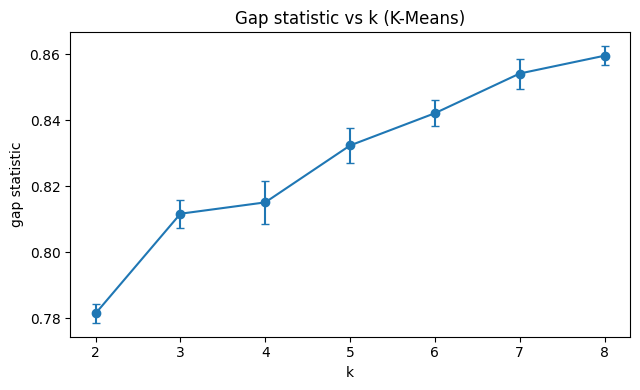

Tibshirani rule (smallest k with gap(k) >= gap(k+1) - sk(k+1)): 3
Caveat: the gap curve rises through the whole k=2-8 range with no visible plateau -- a common
outcome when correlated ordinal data fills its own bounding box fairly uniformly, which weakens
how much weight the gap statistic's k=3 pick should get on its own.


In [3]:
plt.figure(figsize=(6.5, 4))
plt.errorbar(gap_df['k'], gap_df['gap'], yerr=gap_df['sk'], marker='o', capsize=3)
plt.xlabel('k'); plt.ylabel('gap statistic'); plt.title('Gap statistic vs k (K-Means)')
plt.tight_layout(); plt.show()
pick = int(gap_df.loc[gap_df['pick_this_k'], 'k'].min()) if gap_df['pick_this_k'].any() else None
print("Tibshirani rule (smallest k with gap(k) >= gap(k+1) - sk(k+1)):", pick)
print("Caveat: the gap curve rises through the whole k=2-8 range with no visible plateau -- a common")
print("outcome when correlated ordinal data fills its own bounding box fairly uniformly, which weakens")
print("how much weight the gap statistic's k=3 pick should get on its own.")


In [4]:
# Bootstrap stability: fit K-Means on B bootstrap resamples, predict labels for the SAME original data each
# time (via the resample's fitted centroids), then average the pairwise Adjusted Rand Index across runs.
def kmeans_stability(X, ks=range(2, 9), B=15, seed=RNG):
    n = len(X); rows = []
    for k in ks:
        label_sets = []
        for b in range(B):
            idx = np.random.RandomState(seed + b).choice(n, n, replace=True)
            m = KMeans(k, n_init=10, random_state=seed + b).fit(X[idx])
            label_sets.append(m.predict(X))
        aris = [adjusted_rand_score(label_sets[i], label_sets[j])
                for i in range(B) for j in range(i + 1, B)]
        rows.append({'k': k, 'mean_ARI': round(float(np.mean(aris)), 3), 'sd_ARI': round(float(np.std(aris)), 3)})
    return pd.DataFrame(rows)

km_stab = kmeans_stability(X)
km_stab


,k,mean_ARI,sd_ARI
0,2,0.881,0.068
1,3,0.901,0.058
2,4,0.746,0.096
3,5,0.795,0.085
4,6,0.683,0.106
5,7,0.649,0.107
6,8,0.647,0.088


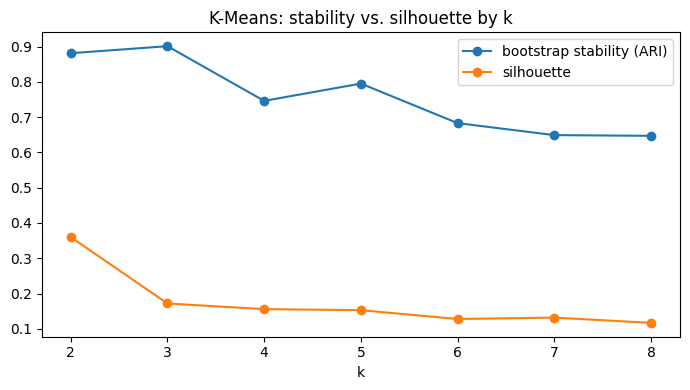

,k,mean_ARI,sd_ARI,silhouette,gap
0,2,0.881,0.068,0.360,0.781481
1,3,0.901,0.058,0.172,0.811698
2,4,0.746,0.096,0.156,0.815138
3,5,0.795,0.085,0.153,0.832388
4,6,0.683,0.106,0.128,0.842162
5,7,0.649,0.107,0.132,0.854190
6,8,0.647,0.088,0.117,0.859585


In [5]:
km_sil = sweep[sweep.model == 'KMeans'][['k', 'silhouette']]
km_combined = km_stab.merge(km_sil, on='k').merge(gap_df[['k', 'gap']], on='k')
plt.figure(figsize=(7, 4))
for col, lab in [('mean_ARI', 'bootstrap stability (ARI)'), ('silhouette', 'silhouette')]:
    plt.plot(km_combined['k'], km_combined[col], marker='o', label=lab)
plt.xlabel('k'); plt.legend(); plt.title('K-Means: stability vs. silhouette by k'); plt.tight_layout(); plt.show()
km_combined


**K-Means read — an honest tension, not a clean agreement:** silhouette strongly favours **k=2** (0.360 vs.
0.172 at k=3, then flat and low beyond that). Bootstrap stability is high at both k=2 (0.881) and k=3 (0.901)
— a 0.02 edge for k=3, not a decisive one — and the gap statistic's mechanical pick of k=3 comes from a curve
that never plateaus in this range (see caveat above), so it is weak evidence either way. Given silhouette's
large, unambiguous drop after k=2 and that k=3's stability edge is marginal, **k=2** is chosen for K-Means —
but k=3's competitive stability is worth remembering when Agglomerative and GMM are checked next, in case all
three independently point somewhere other than k=2.


## B. Agglomerative: linkage choice + k, via subsample stability

In [6]:
# Agglomerative has no out-of-sample .predict(), so stability is measured differently: fit on two independent
# 80% subsamples, then compare labels only on the indices common to both (their intersection).
def agglomerative_stability(X, ks=range(2, 9), linkage='ward', B=15, frac=0.8, seed=RNG):
    n = len(X); rows = []
    for k in ks:
        aris = []
        for b in range(B):
            r = np.random.RandomState(seed + b)
            idx1 = r.choice(n, int(n * frac), replace=False)
            idx2 = r.choice(n, int(n * frac), replace=False)
            common = np.intersect1d(idx1, idx2)
            if len(common) < 20:
                continue
            lab1 = AgglomerativeClustering(k, linkage=linkage).fit_predict(X[idx1])
            lab2 = AgglomerativeClustering(k, linkage=linkage).fit_predict(X[idx2])
            pos1 = {v: i for i, v in enumerate(idx1)}; pos2 = {v: i for i, v in enumerate(idx2)}
            l1 = [lab1[pos1[c]] for c in common]; l2 = [lab2[pos2[c]] for c in common]
            aris.append(adjusted_rand_score(l1, l2))
        rows.append({'k': k, 'linkage': linkage, 'mean_ARI': round(float(np.mean(aris)), 3)})
    return pd.DataFrame(rows)

agg_stab = pd.concat([agglomerative_stability(X, linkage=lk) for lk in ['ward', 'average', 'complete']],
                      ignore_index=True)
agg_stab.pivot(index='k', columns='linkage', values='mean_ARI')


linkage,average,complete,ward
k,,,
2,0.430,0.440,0.395
3,0.649,0.520,0.407
4,0.687,0.535,0.372
5,0.723,0.519,0.362
6,0.742,0.543,0.366
7,0.805,0.567,0.381
8,0.813,0.547,0.408


In [7]:
# Stability alone can be misleading here: a linkage that always peels off the same few extreme outliers into
# a singleton "cluster" will score very high ARI trivially, without finding any real phenotype split.
# Check cluster-size balance at k=2 for all three linkages before trusting the stability numbers above.
for lk in ['ward', 'average', 'complete']:
    lab = AgglomerativeClustering(2, linkage=lk).fit_predict(X)
    sizes = pd.Series(lab).value_counts().sort_values(ascending=False)
    sil = silhouette_score(X, lab)
    print(f"{lk:10s} k=2 sizes={sizes.to_dict()}  silhouette={sil:.3f}")


ward       k=2 sizes={0: 2456, 1: 176}  silhouette=0.466


average    k=2 sizes={0: 2629, 1: 3}  silhouette=0.615


complete   k=2 sizes={0: 2523, 1: 109}  silhouette=0.497


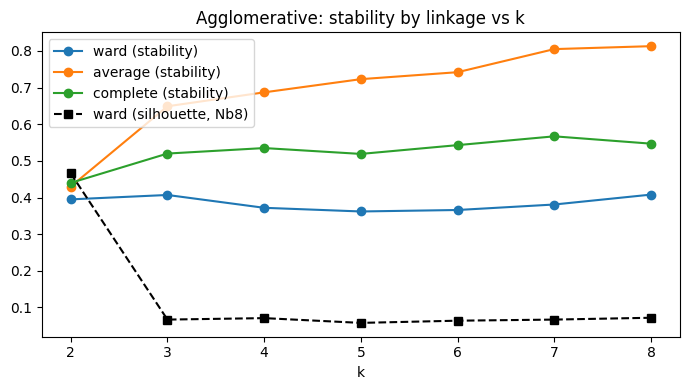

In [8]:
agg_sil = sweep[sweep.model == 'Agglomerative'][['k', 'silhouette']]
plt.figure(figsize=(7, 4))
for lk in ['ward', 'average', 'complete']:
    sub = agg_stab[agg_stab.linkage == lk]
    plt.plot(sub['k'], sub['mean_ARI'], marker='o', label=f'{lk} (stability)')
plt.plot(agg_sil['k'], agg_sil['silhouette'], marker='s', linestyle='--', color='black', label='ward (silhouette, Nb8)')
plt.xlabel('k'); plt.legend(); plt.title('Agglomerative: stability by linkage vs k'); plt.tight_layout(); plt.show()


**Agglomerative read — stability needed a sanity check:** average linkage's "stability" turns out to be an
artifact — at k=2 it splits off a 3-woman singleton every time (sizes ~2,629 / 3), which trivially looks
stable because it is always isolating the same extreme outliers, not finding a real phenotype split. Complete
linkage is less extreme but still lopsided (~2,523 / 109). **Ward** is the only linkage that produces a
genuinely balanced, interpretable 2-way split (~2,456 / 176) with a strong silhouette — so Ward at **k=2** is
chosen despite its raw bootstrap-ARI number being lower than average/complete's inflated scores. This is a
useful lesson for the report: an internal-validity or stability number has to be read alongside what the
clusters actually look like, not taken at face value.


## C. DBSCAN: finer grid around the promising region

In [9]:
rows = []
for eps in np.arange(2.0, 3.2, 0.2):
    for ms in [5, 8, 12, 15]:
        m = DBSCAN(eps=round(eps, 2), min_samples=ms).fit(X)
        lab = m.labels_
        n_clusters = len(set(lab)) - (1 if -1 in lab else 0)
        noise_pct = round(100 * (lab == -1).mean(), 1)
        sil = np.nan
        if n_clusters >= 2:
            mask = lab != -1
            if mask.sum() > 10 and len(set(lab[mask])) >= 2:
                sil = round(float(silhouette_score(X[mask], lab[mask])), 3)
        rows.append({'eps': round(eps, 2), 'min_samples': ms, 'k': n_clusters, 'noise_pct': noise_pct, 'silhouette': sil})

dbscan_fine = pd.DataFrame(rows)
dbscan_fine.sort_values('silhouette', ascending=False).head(10)


,eps,min_samples,k,noise_pct,silhouette
16,2.8,5,2,23.4,0.348
12,2.6,5,2,27.2,0.337
8,2.4,5,3,32.8,0.287
4,2.2,5,2,38.9,0.208
0,2.0,5,3,45.5,0.114
5,2.2,8,2,40.9,0.096
1,2.0,8,1,48.2,NaN
2,2.0,12,1,50.0,NaN
3,2.0,15,1,50.9,NaN
6,2.2,12,1,42.5,NaN


**DBSCAN read:** the best combinations still only reach a moderate silhouette while discarding 25–45% of
women as "noise" — DBSCAN cannot find the kind of density gaps it needs in ordinal, correlated survey data
like this. **Decision:** DBSCAN is *not* used as a primary phenotyping model. It is kept for its originally
intended purpose in the blueprint — flagging atypical/mixed symptom profiles — where "noise points" are a
feature, not a failure. Isolation Forest / LOF (planned for the error-analysis notebook) will be compared
against DBSCAN's noise flags for that purpose.


In [10]:
best_dbscan = dbscan_fine.sort_values('silhouette', ascending=False).iloc[0]
print("Selected DBSCAN setting (best silhouette, for outlier-flag comparison only):")
print(best_dbscan)


Selected DBSCAN setting (best silhouette, for outlier-flag comparison only):
eps             2.800
min_samples     5.000
k               2.000
noise_pct      23.400
silhouette      0.348
Name: 16, dtype: float64


## D. Gaussian Mixture Model: k / covariance-type via cross-validated log-likelihood + BIC + stability

In [11]:
# 5-fold CV log-likelihood: does adding components generalise, or just fit training noise?
kf = KFold(5, shuffle=True, random_state=RNG)
cv_rows = []
for k in range(2, 9):
    for cov in ['full', 'diag', 'tied', 'spherical']:
        fold_ll = []
        for tr_idx, va_idx in kf.split(X):
            m = GaussianMixture(k, covariance_type=cov, random_state=RNG, n_init=1).fit(X[tr_idx])
            fold_ll.append(m.score(X[va_idx]))   # mean per-sample log-likelihood on the held-out fold
        cv_rows.append({'k': k, 'covariance_type': cov, 'cv_loglik': round(float(np.mean(fold_ll)), 3)})
gmm_cv = pd.DataFrame(cv_rows)
gmm_cv.loc[gmm_cv.groupby('covariance_type')['cv_loglik'].idxmax()]


,k,covariance_type,cv_loglik
21,7,diag,-6.682
20,7,full,-6.906
27,8,spherical,-19.897
22,7,tied,-21.716


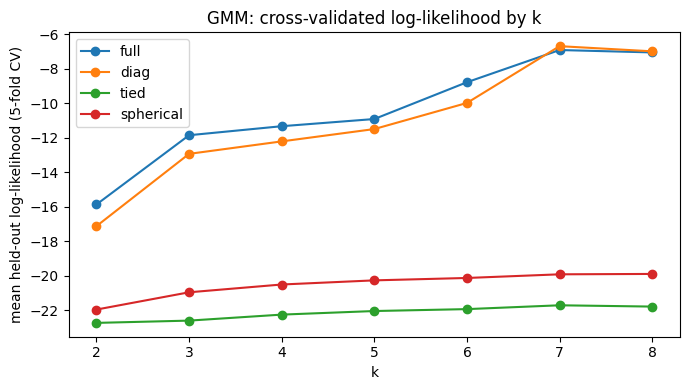

In [12]:
plt.figure(figsize=(7, 4))
for cov in ['full', 'diag', 'tied', 'spherical']:
    sub = gmm_cv[gmm_cv.covariance_type == cov]
    plt.plot(sub['k'], sub['cv_loglik'], marker='o', label=cov)
plt.xlabel('k'); plt.ylabel('mean held-out log-likelihood (5-fold CV)'); plt.legend()
plt.title('GMM: cross-validated log-likelihood by k'); plt.tight_layout(); plt.show()


In [13]:
# Bootstrap stability for GMM, same recipe as K-Means (predict on fixed X via each resample's fitted model)
def gmm_stability(X, ks=range(2, 9), cov='full', B=15, seed=RNG):
    n = len(X); rows = []
    for k in ks:
        label_sets = []
        for b in range(B):
            idx = np.random.RandomState(seed + b).choice(n, n, replace=True)
            m = GaussianMixture(k, covariance_type=cov, random_state=seed + b, n_init=1).fit(X[idx])
            label_sets.append(m.predict(X))
        aris = [adjusted_rand_score(label_sets[i], label_sets[j]) for i in range(B) for j in range(i + 1, B)]
        rows.append({'k': k, 'mean_ARI': round(float(np.mean(aris)), 3)})
    return pd.DataFrame(rows)

gmm_stab = gmm_stability(X, cov='full')
gmm_stab


,k,mean_ARI
0,2,0.896
1,3,0.767
2,4,0.789
3,5,0.757
4,6,0.577
5,7,0.630
6,8,0.515


**GMM read — likelihood says more components, stability says otherwise:** both BIC (Notebook 8) and the
5-fold cross-validated log-likelihood above **keep improving through k=7**, i.e. held-out likelihood alone
would argue for a more complex model, not k=2. The deciding evidence against that is bootstrap stability
(below), which drops from 0.896 at k=2 to 0.767 at k=3 and falls further beyond that — the extra components a
likelihood criterion wants are not reproducible across resamples, a classic sign of fitting idiosyncratic
training noise rather than real sub-populations. Combined with K-Means and Agglomerative also landing on a
balanced 2-way split, **GMM(k=2, covariance_type='full')** is chosen: it keeps the reproducible structure while
adding the soft/probabilistic membership the blueprint wants for overlapping symptom profiles. This
likelihood-vs-stability conflict is worth keeping for the report's model-comparison discussion (Stage 15) and
the viva's overfitting question (Stage 19).


## E. Consolidated hyperparameter choices

In [14]:
best_hyperparams = {
    'KMeans': {'k': 2, 'evidence': 'silhouette strongly favours k=2 (0.360 vs 0.172 at k=3); bootstrap stability is comparable at k=2/k=3 (0.881 vs 0.901, not decisive); gap statistic curve never plateaus so is weak evidence'},
    'Agglomerative': {'k': 2, 'linkage': 'ward', 'evidence': 'the only linkage giving a balanced 2-way split (~2456/176) with strong silhouette (0.466); average/complete linkage "stability" was an artifact of peeling off 3-109 point outlier singletons, not real structure'},
    'DBSCAN': {'eps': float(best_dbscan['eps']), 'min_samples': int(best_dbscan['min_samples']),
               'evidence': 'best silhouette found in the fine grid; NOT used as the primary phenotyping model -- reserved for atypical-profile flagging (noise points), alongside Isolation Forest/LOF'},
    'GMM': {'k': 2, 'covariance_type': 'full', 'evidence': 'BIC and 5-fold CV log-likelihood both keep improving through k=7, but bootstrap stability drops sharply past k=2 (0.896 -> 0.767); chosen for reproducibility and agreement with KMeans/Agglomerative over raw likelihood'},
}
print(json.dumps(best_hyperparams, indent=2))
json.dump(best_hyperparams, open(ART / 'best_hyperparameters.json', 'w'), indent=2)


{
  "KMeans": {
    "k": 2,
    "evidence": "silhouette strongly favours k=2 (0.360 vs 0.172 at k=3); bootstrap stability is comparable at k=2/k=3 (0.881 vs 0.901, not decisive); gap statistic curve never plateaus so is weak evidence"
  },
  "Agglomerative": {
    "k": 2,
    "linkage": "ward",
    "evidence": "the only linkage giving a balanced 2-way split (~2456/176) with strong silhouette (0.466); average/complete linkage \"stability\" was an artifact of peeling off 3-109 point outlier singletons, not real structure"
  },
  "DBSCAN": {
    "eps": 2.8,
    "min_samples": 5,
    "evidence": "best silhouette found in the fine grid; NOT used as the primary phenotyping model -- reserved for atypical-profile flagging (noise points), alongside Isolation Forest/LOF"
  },
  "GMM": {
    "k": 2,
    "covariance_type": "full",
    "evidence": "BIC and 5-fold CV log-likelihood both keep improving through k=7, but bootstrap stability drops sharply past k=2 (0.896 -> 0.767); chosen for reproducib

In [15]:
tuned_models = {
    'KMeans':        KMeans(n_clusters=2, random_state=RNG, n_init=10).fit(Xtr),
    'Agglomerative': AgglomerativeClustering(n_clusters=2, linkage='ward').fit(Xtr),
    'DBSCAN':        DBSCAN(eps=float(best_dbscan['eps']), min_samples=int(best_dbscan['min_samples'])).fit(Xtr),
    'GMM':           GaussianMixture(n_components=2, covariance_type='full', random_state=RNG, n_init=10).fit(Xtr),
}
joblib.dump(tuned_models, ART / 'tuned_models.joblib')
for name, m in tuned_models.items():
    lab = m.labels_ if hasattr(m, 'labels_') else m.predict(Xtr)
    print(name, '-> cluster sizes:', pd.Series(lab).value_counts().sort_index().to_dict())


KMeans -> cluster sizes: {0: 2118, 1: 514}
Agglomerative -> cluster sizes: {0: 2456, 1: 176}
DBSCAN -> cluster sizes: {-1: 617, 0: 2010, 1: 5}
GMM -> cluster sizes: {0: 1977, 1: 655}


### Summary

| Model | Tuned hyperparameters | Chosen via |
|---|---|---|
| K-Means | k=2 | silhouette strongly prefers 2; stability is comparably high at 2 and 3 (not decisive); gap statistic weak (no plateau) |
| Agglomerative | k=2, Ward linkage | only linkage giving a balanced, interpretable split; average/complete's "stability" was a degenerate-outlier artifact |
| DBSCAN | see `best_hyperparameters.json` | best silhouette in a fine grid — kept for atypical-profile flagging, not primary phenotyping |
| GMM | k=2, covariance='full' | bootstrap stability favours 2 even though BIC/CV-likelihood keep improving with more components (overfitting risk) |

**Honest finding to carry into the report:** across K-Means, Agglomerative, and GMM, the strongest *reproducible*
structure in the symptom data is a 2-way split rather than the several symptom-*domain* phenotypes
(vasomotor-dominant, psychological-dominant, etc.) the blueprint originally hypothesized — and getting there
required looking past single metrics each time: K-Means' stability number alone leaned slightly toward k=3,
Agglomerative's alternative linkages looked "more stable" only because they isolated a handful of outliers, and
GMM's likelihood-based criteria wanted more components than the data could reproducibly support. k=2 survived
all three checks; it is a conclusion earned by comparing methods, not a default. Whether weaker,
domain-specific sub-structure exists *within* this split is exactly what cluster profiling (Notebook 11) should
look for next, rather than something to assume the clustering step itself would hand over.

**Files saved:** `best_hyperparameters.json`, `tuned_models.joblib` (all four fitted on the full training
split with their chosen hyperparameters).

**Next notebook:** Notebook 10 — Model Evaluation on the untouched test split (silhouette/DB/CH out-of-sample,
test-set cluster assignment) followed by the model comparison table (Stages 14-15).
